# Performance evaluation for **bamcmp**

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path("/omics/groups/OE0219/internal/altendorfer/epiproper/read_sorting_benchmark/data")
method = "bamcmp" 
fig_dir = Path.cwd() / "figures" / method
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [9]:
df = read_evaluations(data_dir, method)
df.groupby(["Sample_Prefix", "Total_Reads"]).count()
df.head()

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Mouse_Assigned,Amb_Human_Assigned,Amb_Mouse_Assigned,Human_Human,Human_Mouse,Mouse_Mouse,Mouse_Human,Amb_Human_Human,Amb_Human_Mouse,Amb_Mouse_Mouse,Amb_Mouse_Human,Sample_Name
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,0,0,13937318,6062682,0,0,0,0,13915298,22020,5977980,84702,Mixture 4
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,0,0,13937539,6062461,0,0,0,0,13915563,21976,5978024,84437,Mixture 4
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,0,0,13937201,6062799,0,0,0,0,13915275,21926,5978074,84725,Mixture 4
3,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,3,0,0,13937763,6062237,0,0,0,0,13915776,21987,5978013,84224,Mixture 4
4,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,4,0,0,13937438,6062562,0,0,0,0,13915523,21915,5978085,84477,Mixture 4


In [10]:
df["Human_Ratio"] = df["Mixture"]
#df["Mixture"] = [f"{mix_num * 100}p" for mix_num in df["Mixture"]]

## Visualize assigned reads

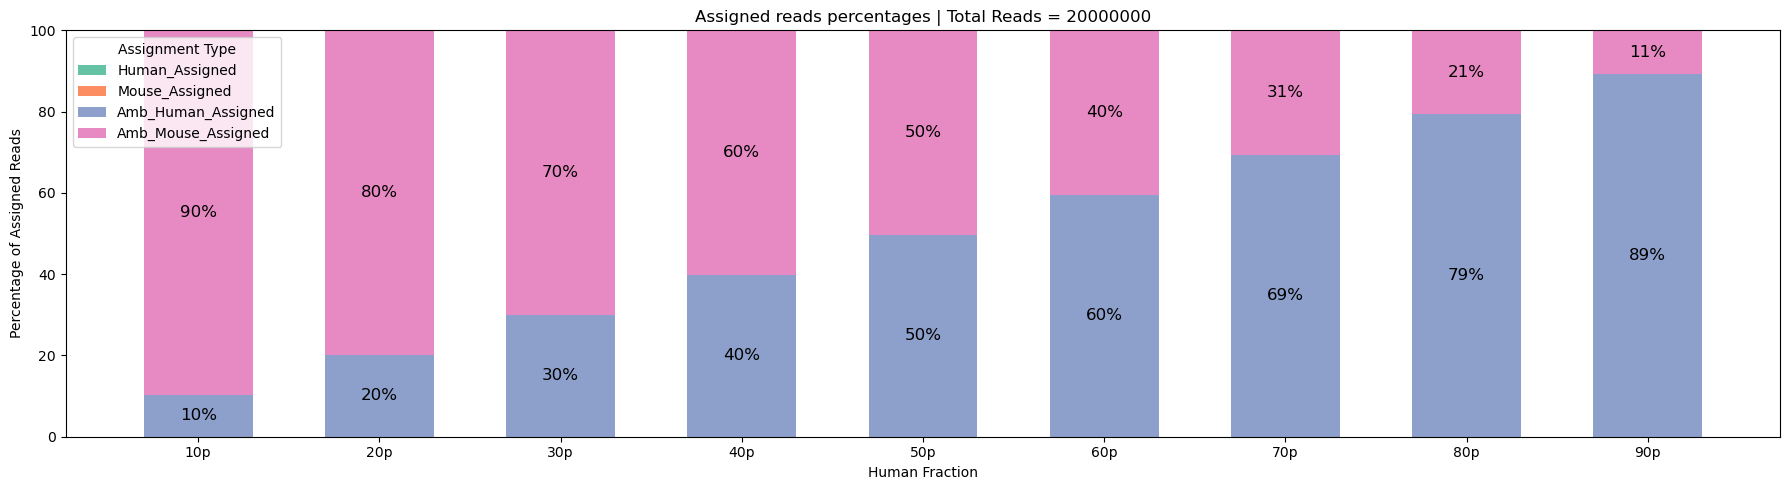

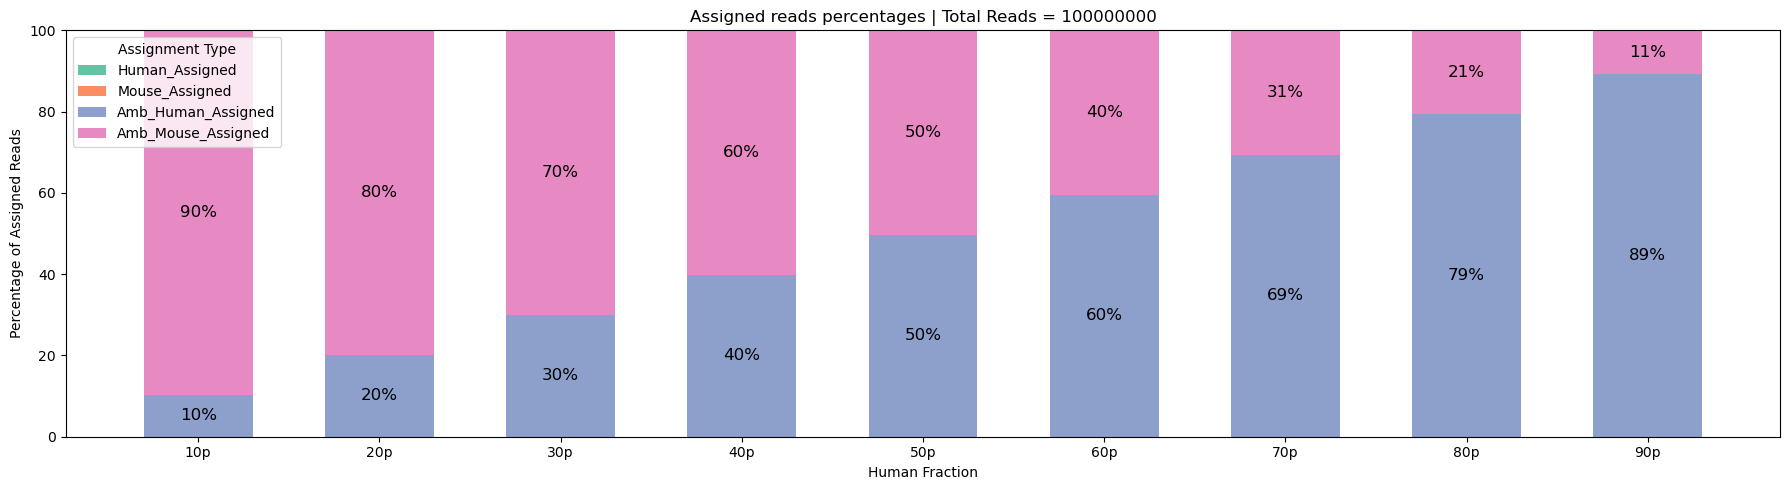

In [11]:
plot_assignment_bars_by_total_reads_stacked(df, assigned_cols=["Human_Assigned", "Mouse_Assigned", "Amb_Human_Assigned", "Amb_Mouse_Assigned"])

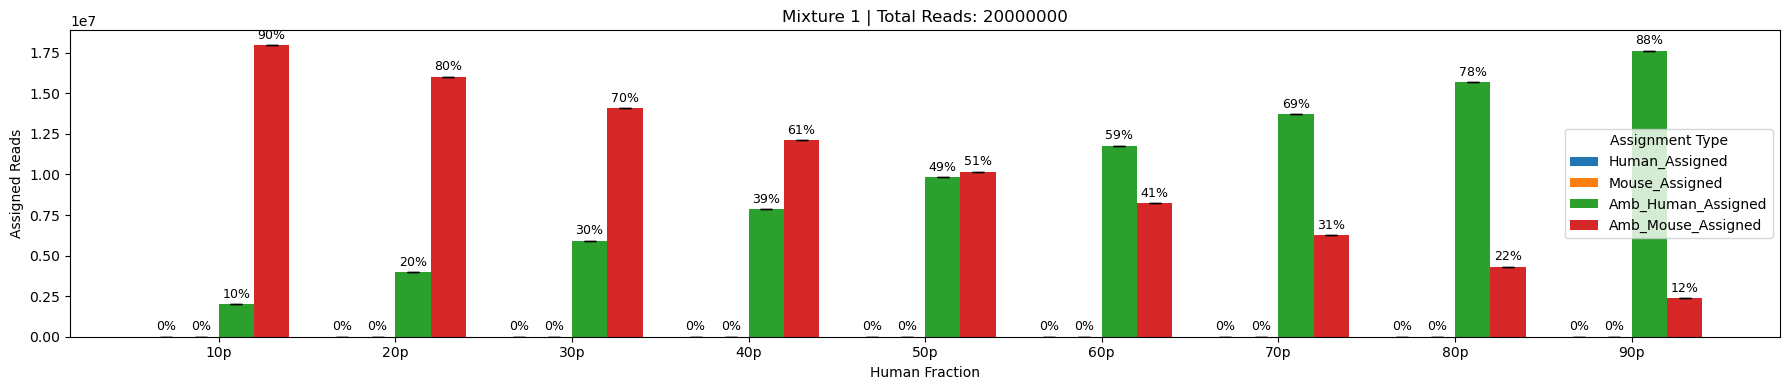

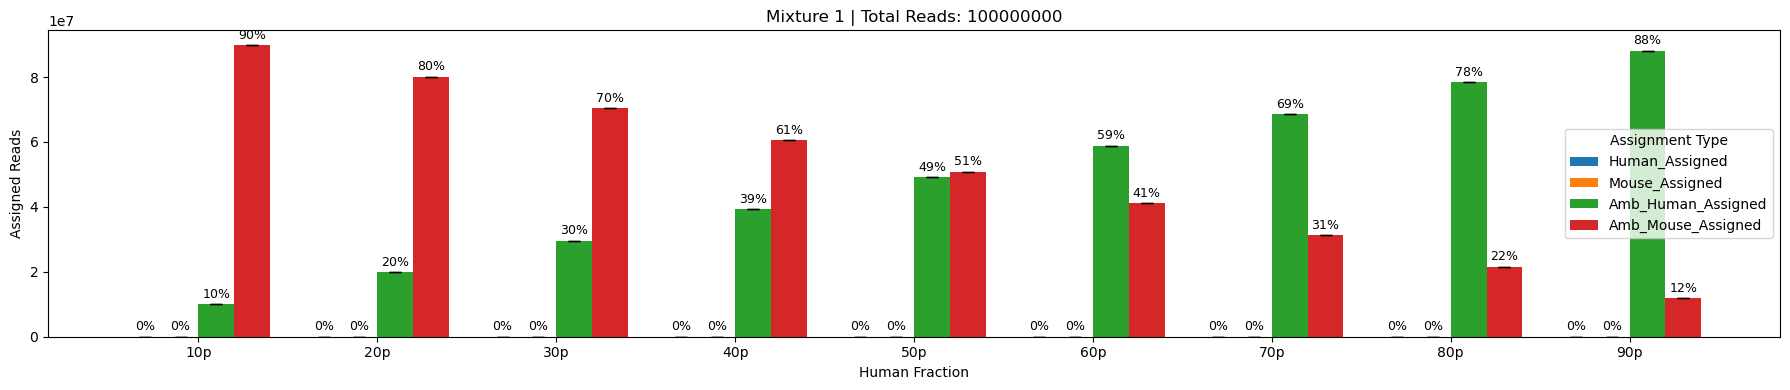

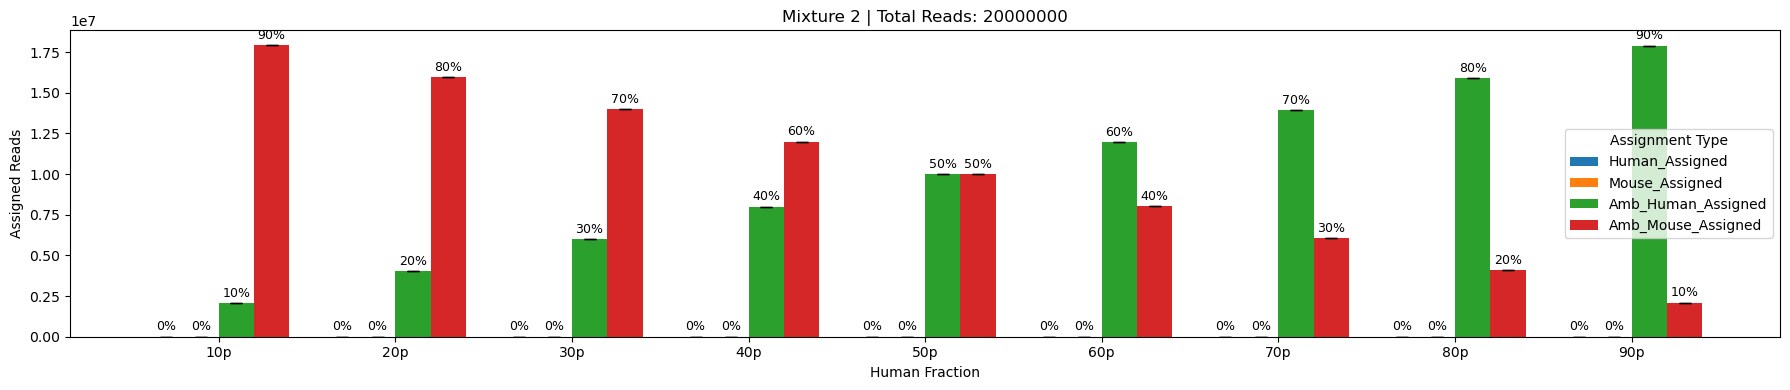

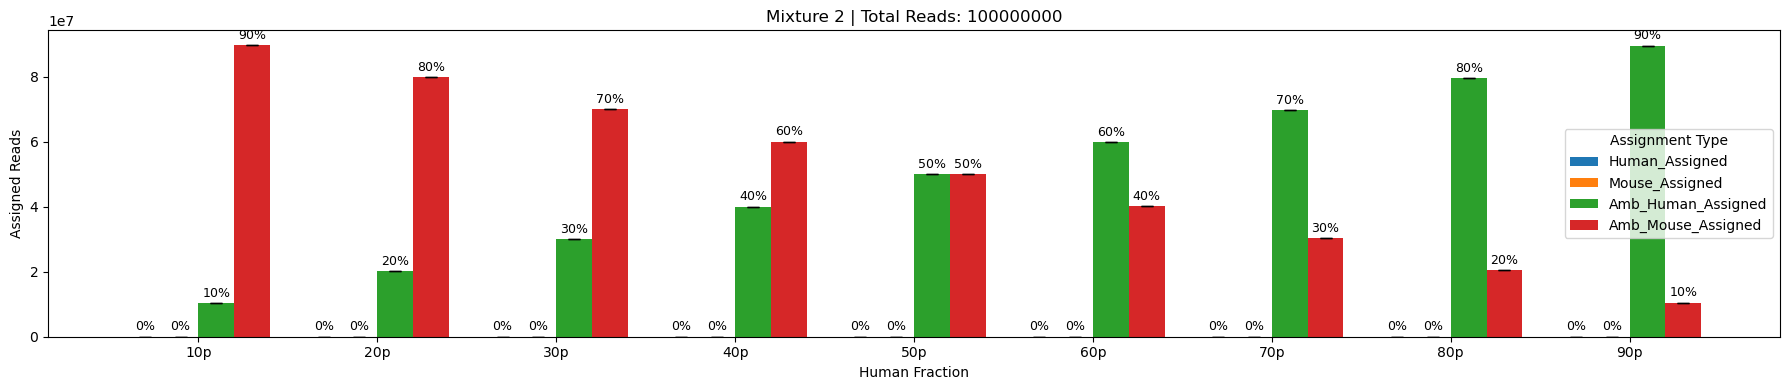

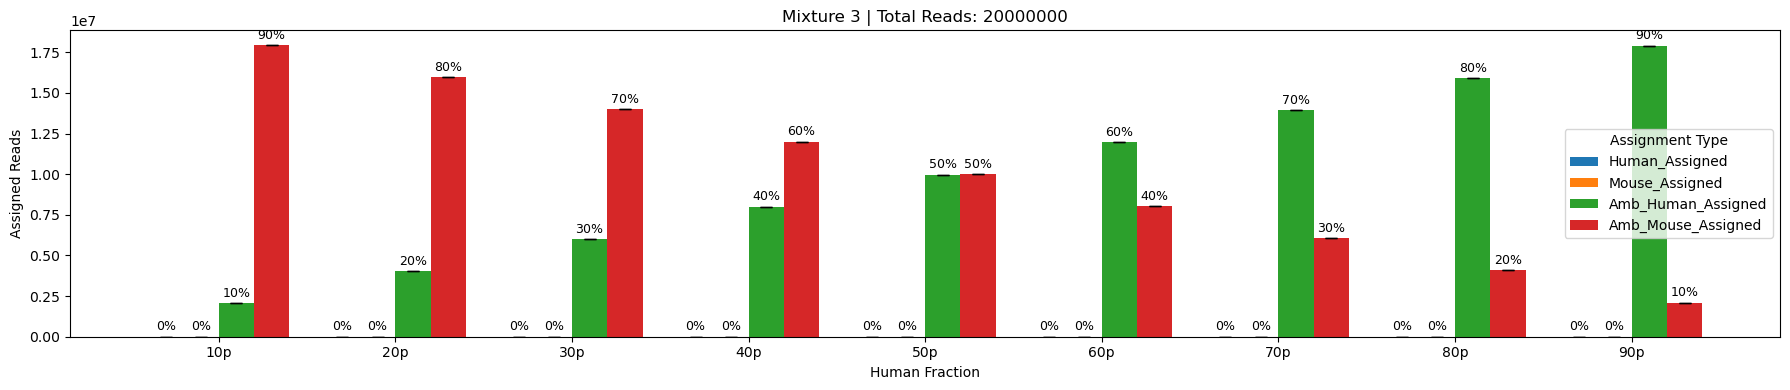

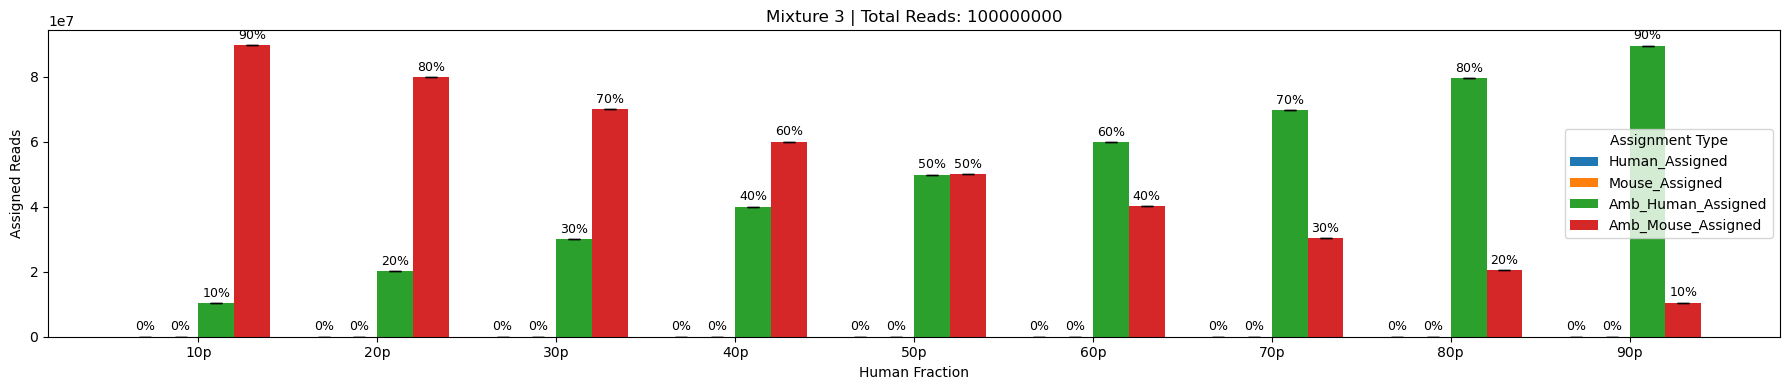

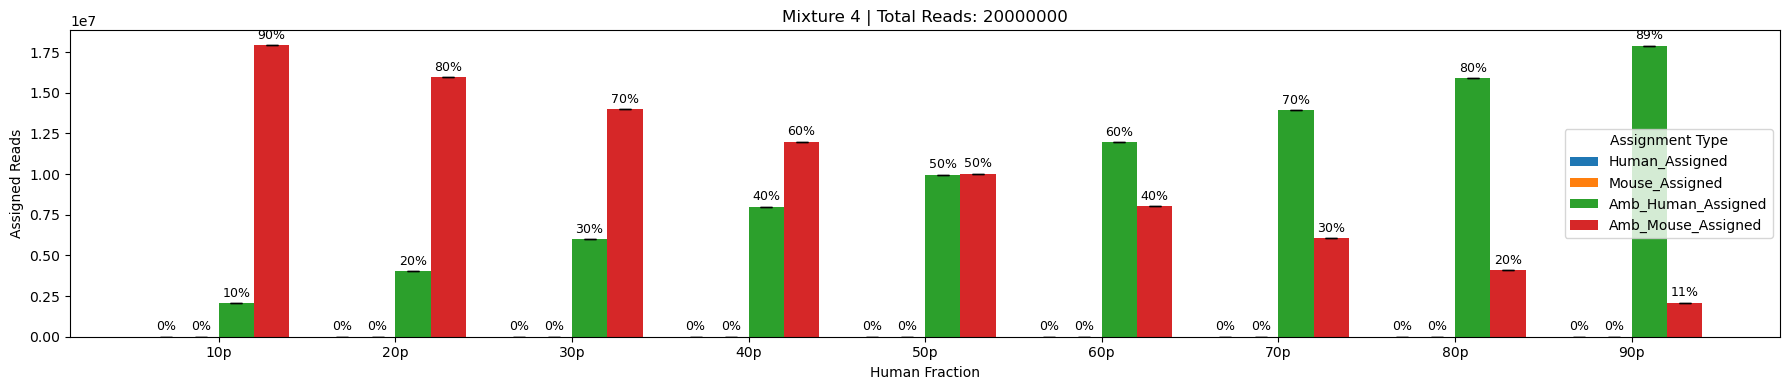

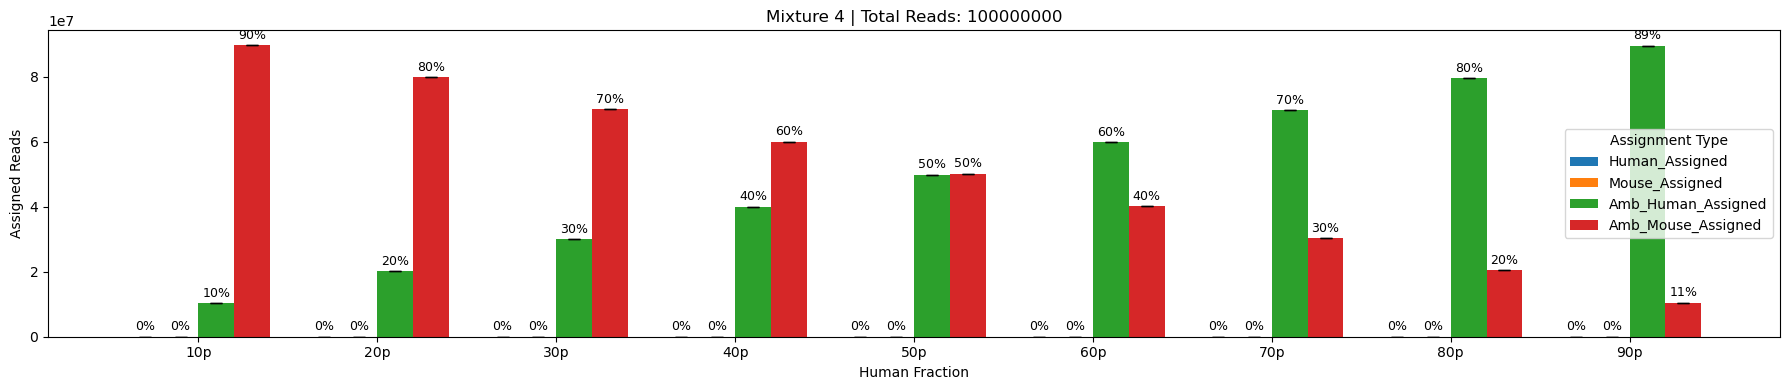

In [12]:
plot_assignment_bars(df, assigned_cols=["Human_Assigned", "Mouse_Assigned", "Amb_Human_Assigned", "Amb_Mouse_Assigned"], save=True, fig_dir=fig_dir)

Due to the constrained DNA alphabet in whole genome bisulfite sequencing, bamcmp assings more reads to the class ambiguous and only few are clearly classified as human or mouse. \
&rarr; We need to consider *ambigousHuman* and *ambiguousMouse* for the confusion matrix.


## Confusion Matrix

In [13]:
df_conf = assign_confusion_matrix(df, method="bamcmp")

### Without ambiguous reads

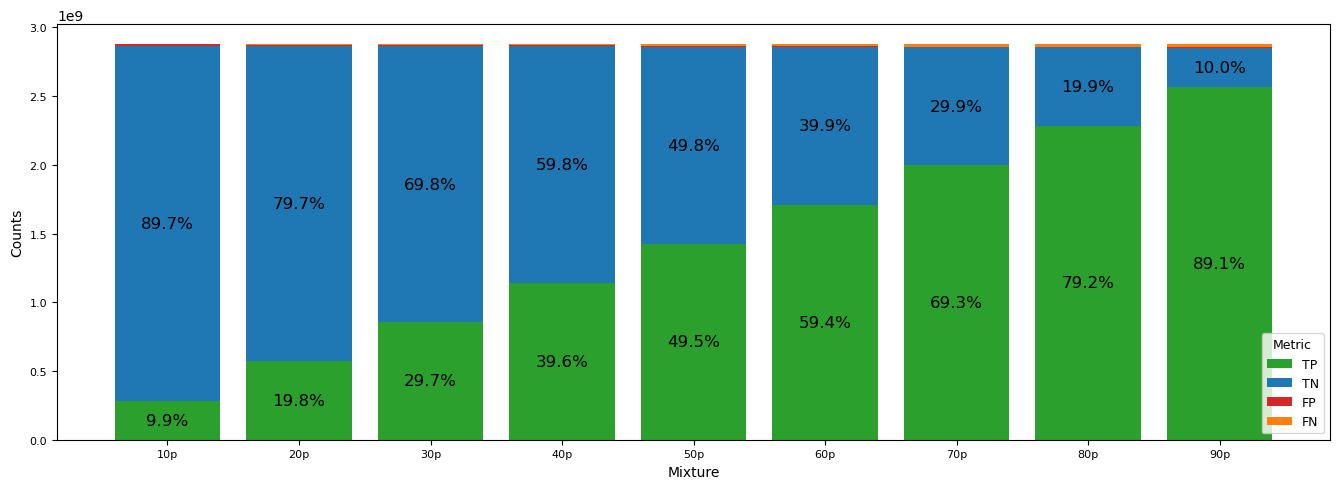

In [14]:
plot_stacked_confusion_bar(
    df_conf,
    save=True,
    fig_dir=fig_dir
)


## Calculate performance metrics

In [15]:
df_metrics = calculate_metrics(df_conf)
df_metrics.head(3)

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Mouse_Assigned,Amb_Human_Assigned,Amb_Mouse_Assigned,Human_Human,...,Accuracy,Recall,FPR,Precision,F1,MCC,Human_Loss,Contamination_Rate,Mouse_Leakage,Score
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,0,0,13937318,6062682,0,...,0.994664,0.993950,0.003670,0.998420,0.996180,0.987360,0.006050,0.001580,0.003670,0.997079
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,0,0,13937539,6062461,0,...,0.994679,0.993969,0.003663,0.998423,0.996191,0.987396,0.006031,0.001577,0.003663,0.997087
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,0,0,13937201,6062799,0,...,0.994667,0.993948,0.003654,0.998427,0.996182,0.987369,0.006052,0.001573,0.003654,0.997083


## Visualize performance metrics

### By total reads, for each sample

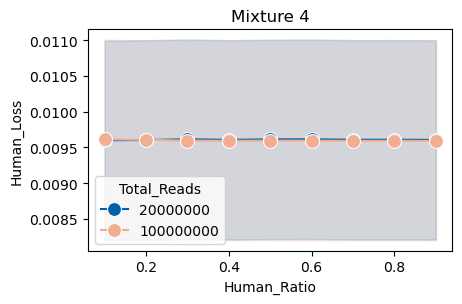

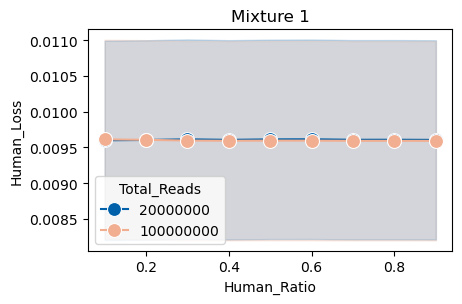

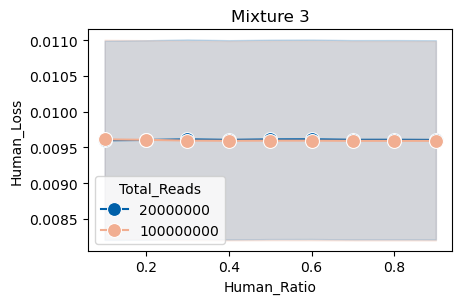

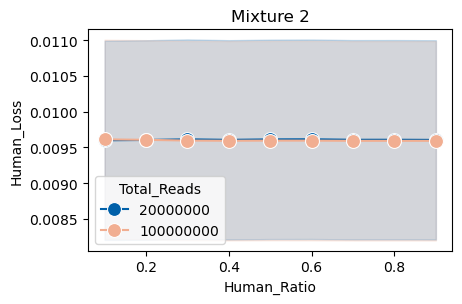

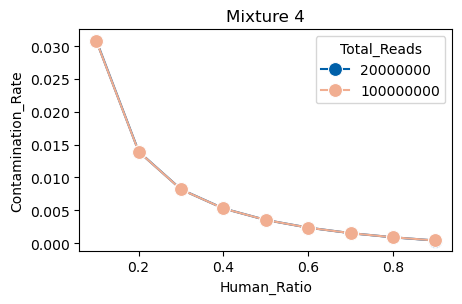

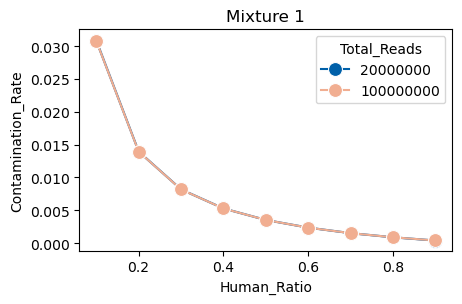

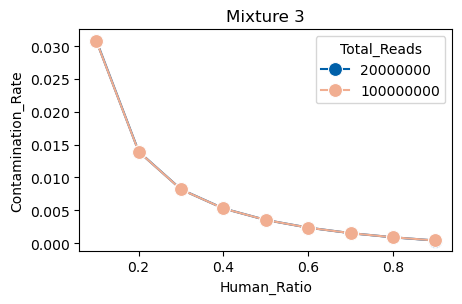

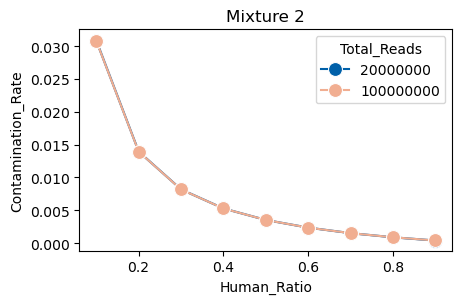

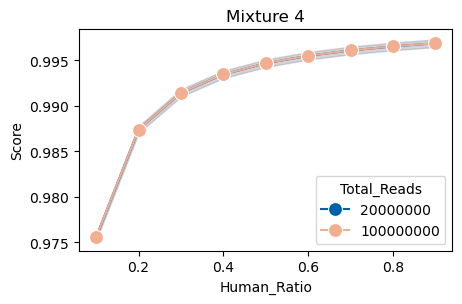

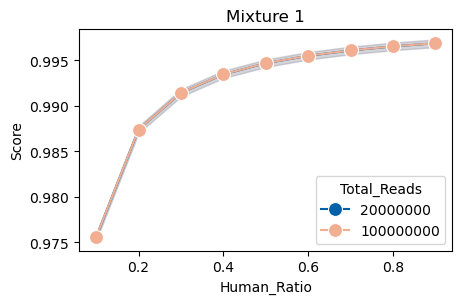

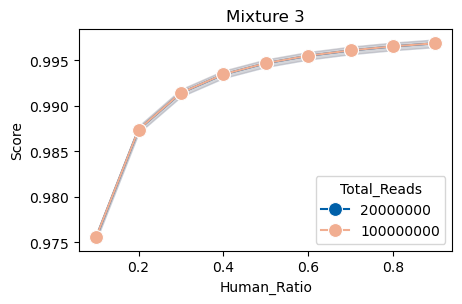

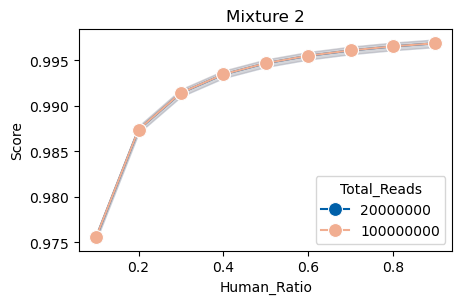

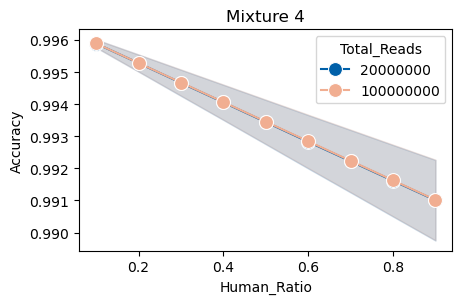

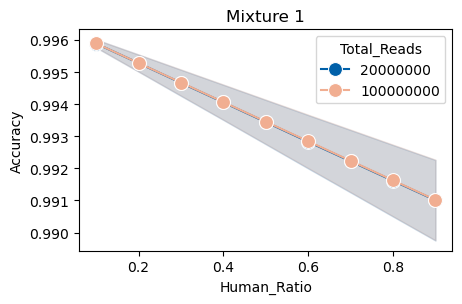

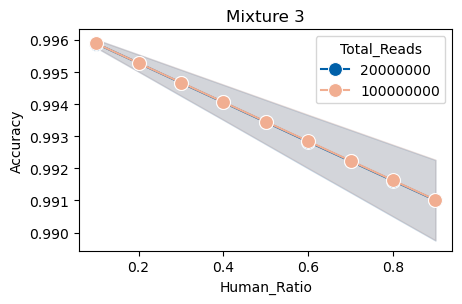

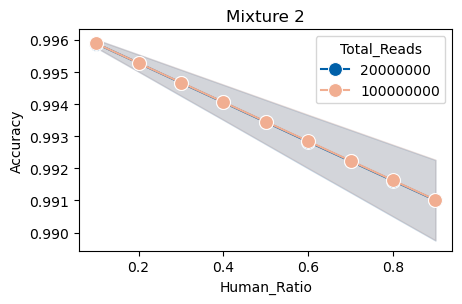

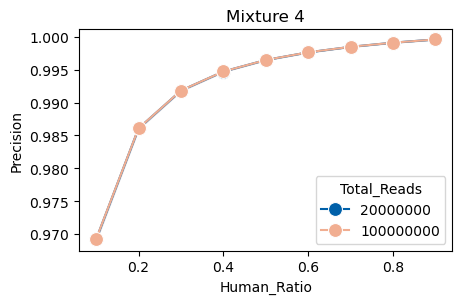

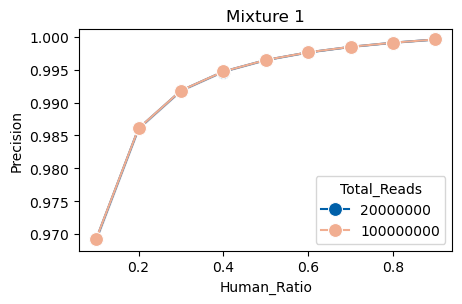

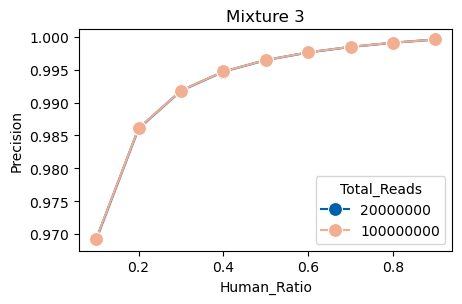

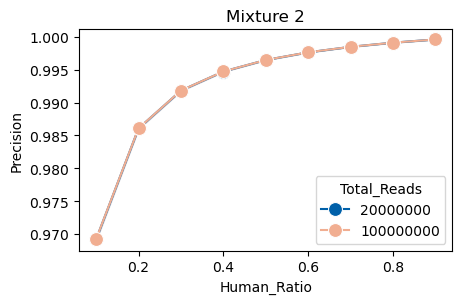

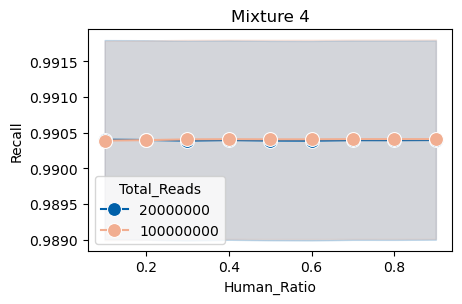

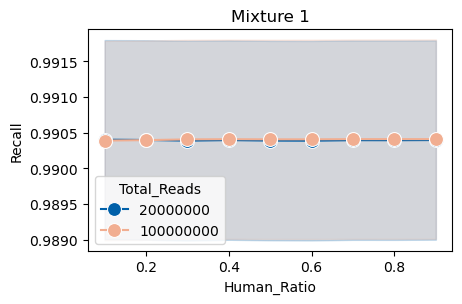

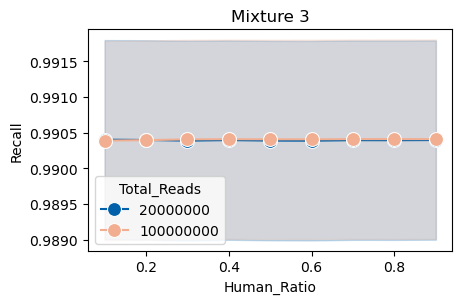

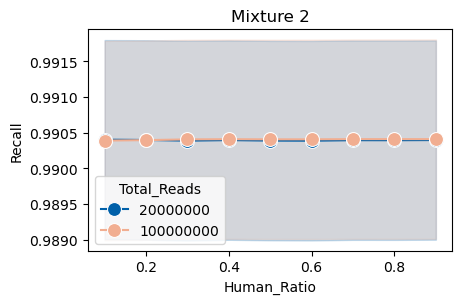

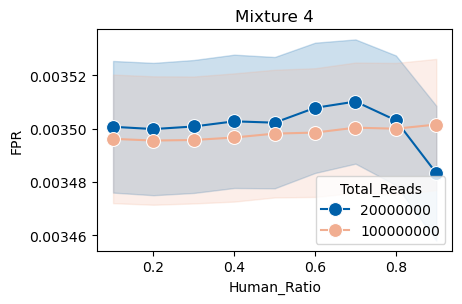

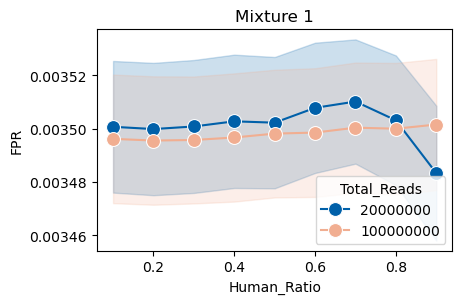

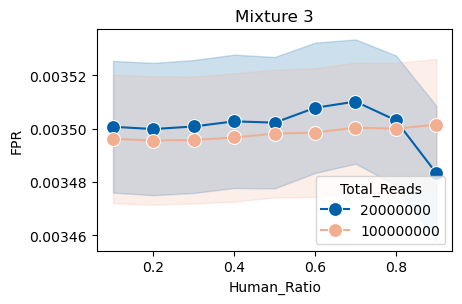

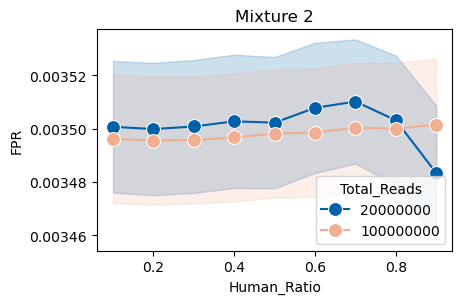

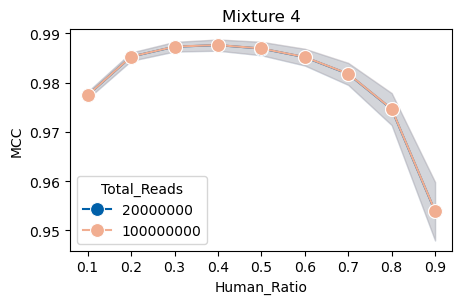

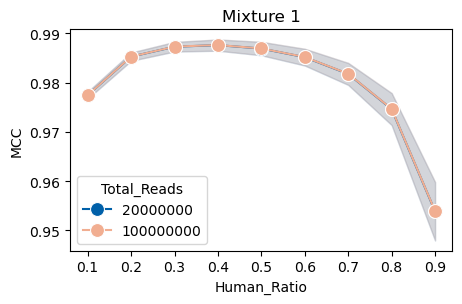

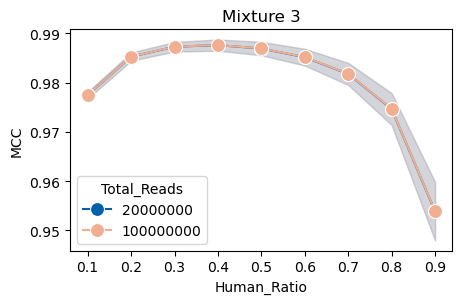

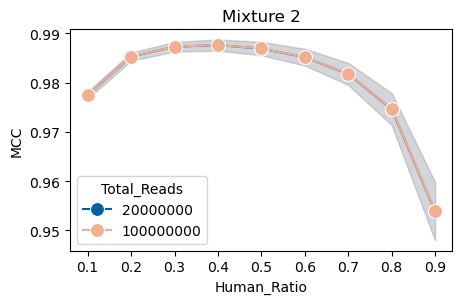

In [16]:
metrics = ["Human_Loss", "Contamination_Rate", "Score", "Accuracy", "Precision", "Recall", "FPR", "MCC"]
figsize=mm_to_inches((120, 80))
for metric in metrics:
    errorplot_by_reads(df_metrics, metric=metric, save=True, fig_dir=fig_dir, palette=dkfz_colors, figsize=figsize)



### Across samples

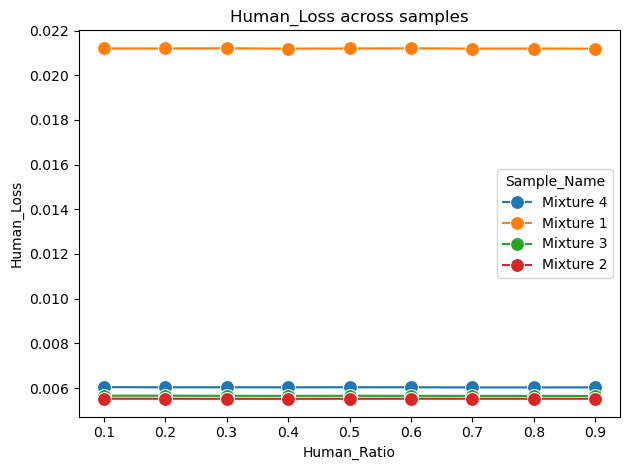

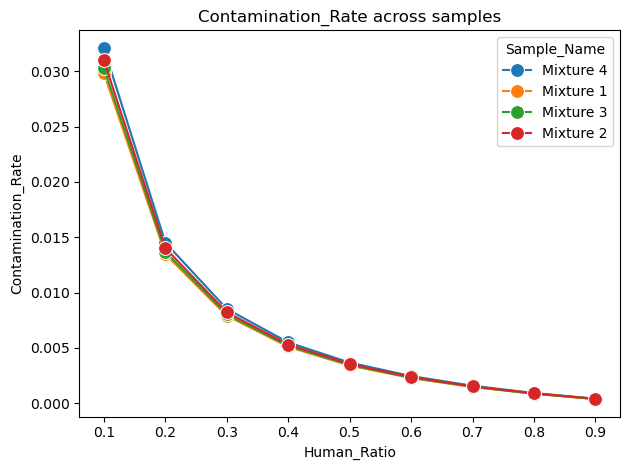

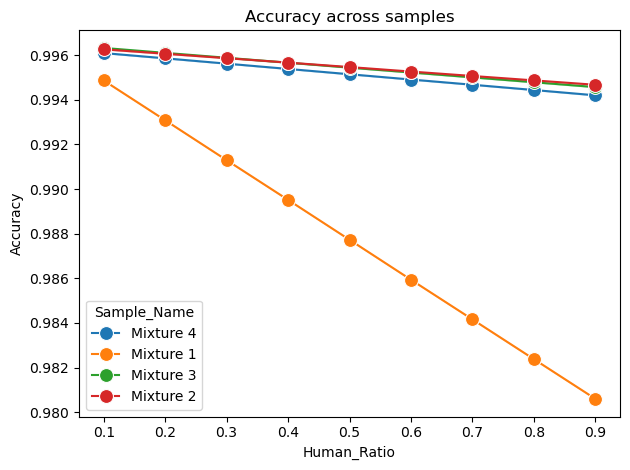

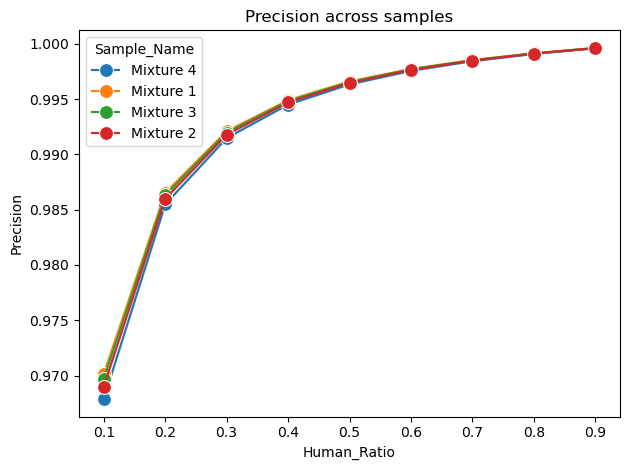

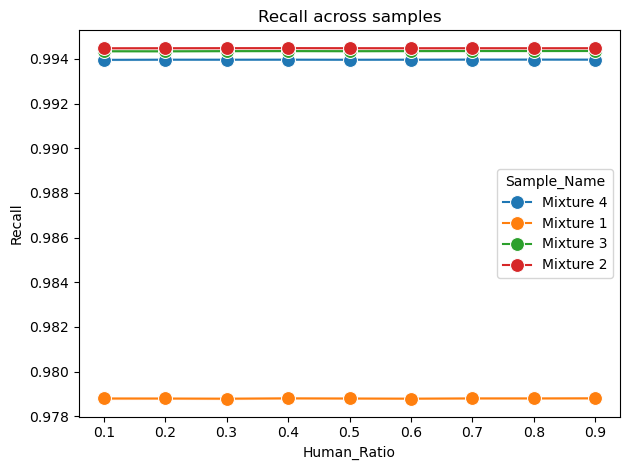

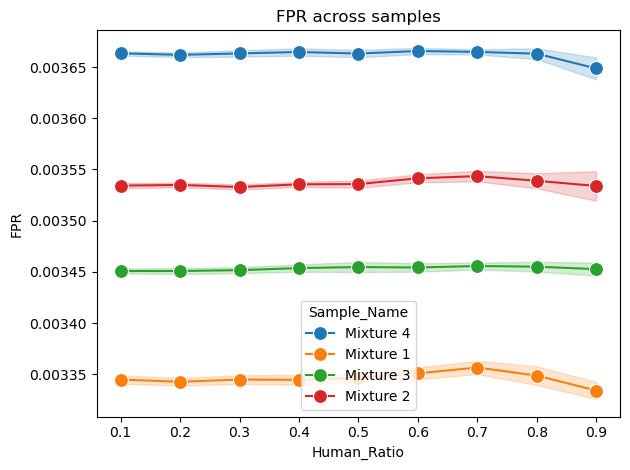

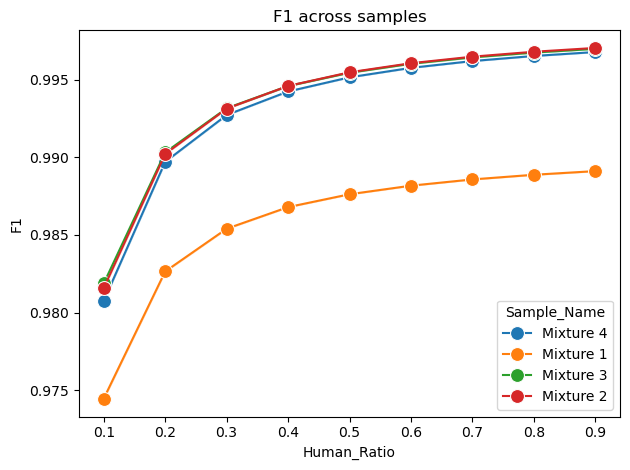

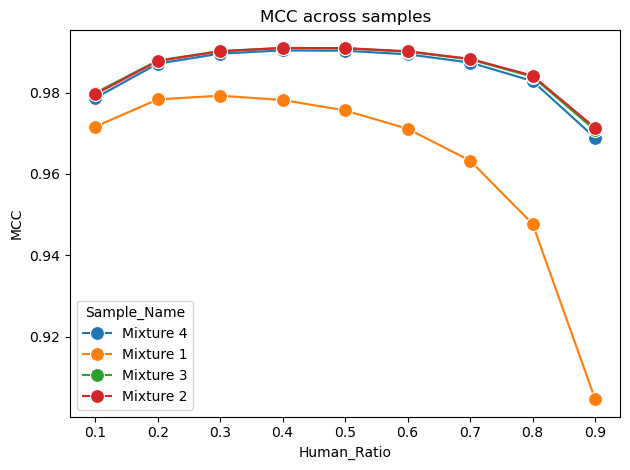

In [17]:
errorplot_by_sample(df_metrics, metric="Human_Loss")
errorplot_by_sample(df_metrics, metric="Contamination_Rate")
errorplot_by_sample(df_metrics)
errorplot_by_sample(df_metrics, metric="Precision")
errorplot_by_sample(df_metrics, metric="Recall")
errorplot_by_sample(df_metrics, metric="FPR")
errorplot_by_sample(df_metrics, metric="F1")
errorplot_by_sample(df_metrics, metric="MCC")

### Boxplots across samples

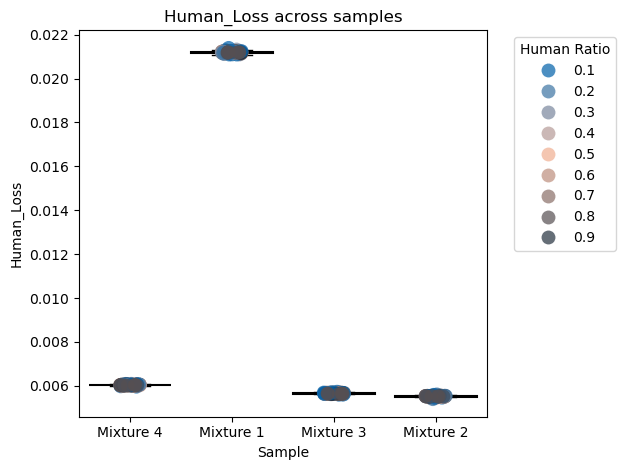

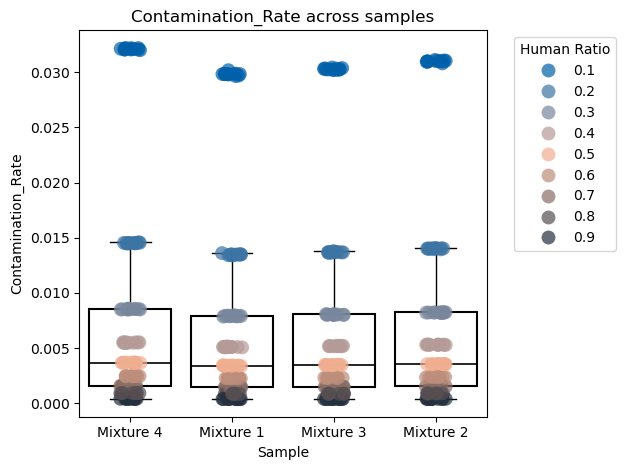

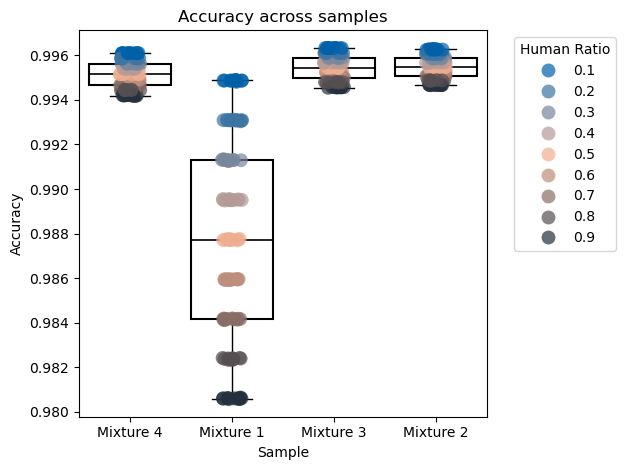

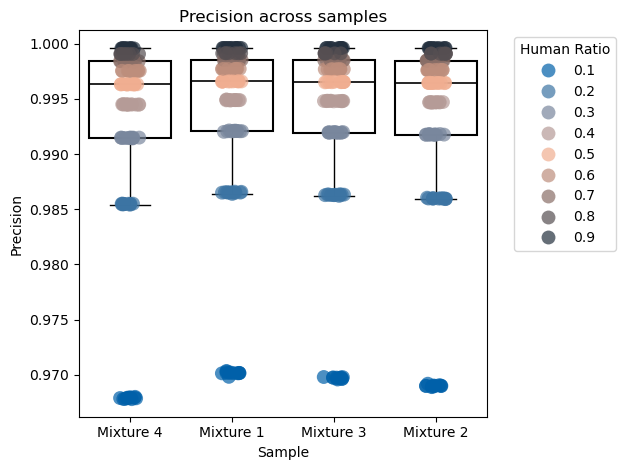

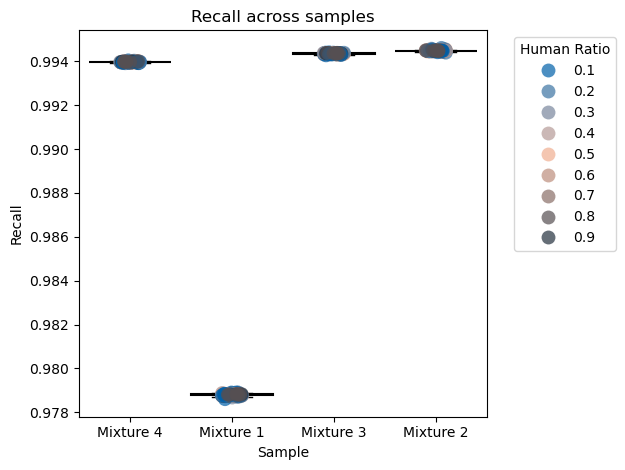

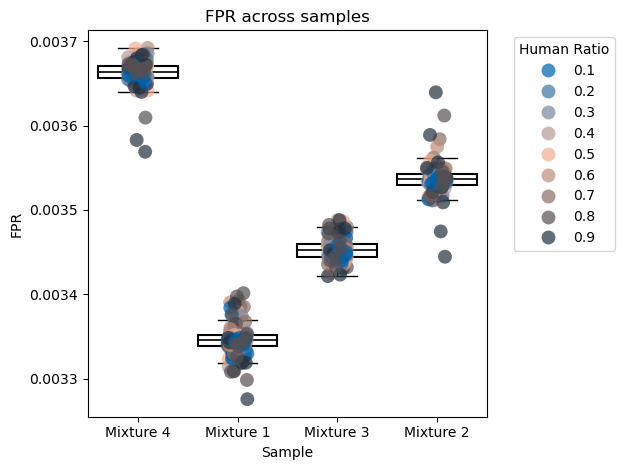

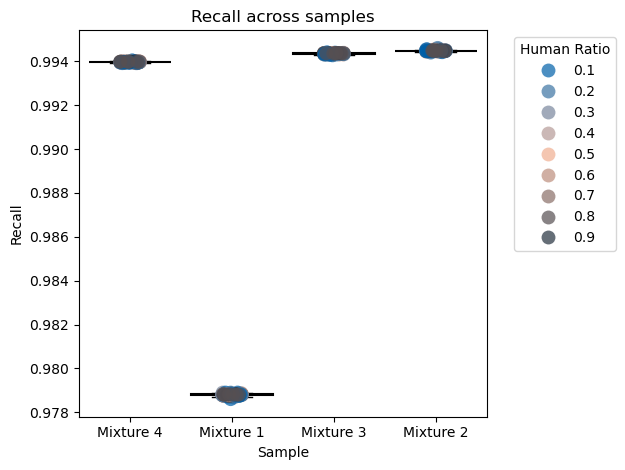

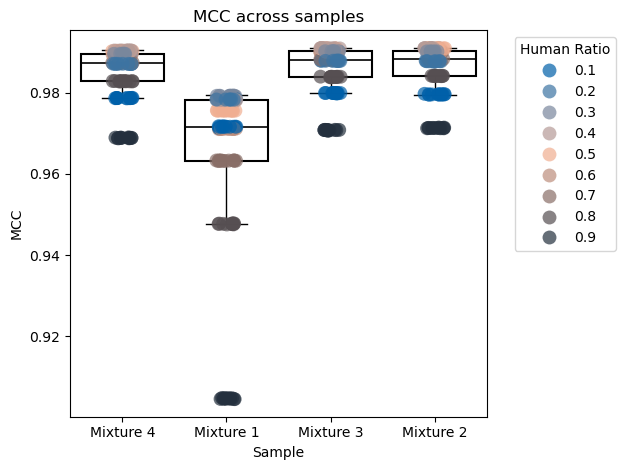

In [18]:
boxplot_by_samples(df_metrics, metric="Human_Loss")
boxplot_by_samples(df_metrics, metric="Contamination_Rate")
boxplot_by_samples(df_metrics)
boxplot_by_samples(df_metrics, metric="Precision")
boxplot_by_samples(df_metrics, metric="Recall")
boxplot_by_samples(df_metrics, metric="FPR")
boxplot_by_samples(df_metrics, metric="Recall")
boxplot_by_samples(df_metrics, metric="MCC")

## Save dataframe

In [19]:
df_metrics["Method"] = "bamcmp"

In [20]:
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "bamcmp.csv", index=False)